# Renewable Energy Transition Across Countries
## Milestone 3: Visual drafts
These charts compare renewable energy adoption and selected renewable electricity pathways across ten countries in 2024. The target audience is university peers and readers interested in energy policy who need clear comparisons without specialist knowledge.

Total energy and electricity generation have different denominators; the two charts should be read separately. Source: Our World in Data Energy Dataset, using the project's cleaned CSV.

**Measure definitions.** Visual 1 uses the renewable share of **primary energy consumption**, calculated with the substitution method; it is not a share of final energy consumption. Visual 2 uses solar, wind, and hydro shares of **total electricity generation**. Their common electricity denominator makes them suitable for stacking, but their percentages must not be compared directly with Visual 1.

Definitions and attribution were checked against `data/energy_source/owid-energy-codebook.csv`. [Our World in Data Energy Dataset documentation](https://github.com/owid/energy-data) describes this legacy dataset; the project uses its saved source snapshot, rather than a live download.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Resolve paths from either the repository root or notebooks/ in VS Code.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/energy_10countries_clean.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project repository.")
OUTPUT = ROOT / "visuals"
OUTPUT.mkdir(exist_ok=True)
YEAR = 2024
SHARES = ["renewables_share_energy", "solar_share_elec",
          "wind_share_elec", "hydro_share_elec"]
data = pd.read_csv(ROOT / "data/energy_10countries_clean.csv")
frame = (data.loc[data["year"].eq(YEAR), ["country", *SHARES]]
         .sort_values("renewables_share_energy", ascending=False)
         .reset_index(drop=True))
COUNTRIES = {"Brazil", "China", "Denmark", "France", "Germany", "India",
             "Japan", "Norway", "South Africa", "United States"}
assert len(frame) == 10 and set(frame["country"]) == COUNTRIES, "Unexpected country selection."
assert not data.duplicated(["country", "year"]).any(), "Duplicate country-year rows."
assert frame[SHARES].notna().all().all(), "Missing chart values."
assert frame[SHARES].ge(0).all().all() and frame[SHARES].le(100).all().all()
assert frame[SHARES[1:]].sum(axis=1).le(100.01).all()

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.spines.left": False, "axes.spines.bottom": False,
                     "axes.labelcolor": "#334155", "text.color": "#172B3A",
                     "xtick.color": "#526171", "ytick.color": "#172B3A",
                     "figure.facecolor": "white", "axes.facecolor": "white"})

def chart_frame(headline, subtitle, footer):
    fig, ax = plt.subplots(figsize=(12, 7.5))
    fig.subplots_adjust(left=0.16, right=0.95, top=0.79, bottom=0.19)
    fig.text(0.055, 0.95, headline, fontsize=18, weight="bold", va="top")
    fig.text(0.055, 0.89, subtitle, fontsize=12, color="#526171", va="top")
    fig.text(0.055, 0.045, footer, fontsize=9, color="#526171", va="bottom")
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.8)
    ax.tick_params(axis="both", length=0, pad=8)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    return fig, ax

print(f"Loaded {len(frame)} countries for {YEAR}; output folder: {OUTPUT}")

Loaded 10 countries for 2024; output folder: c:\Users\ghada\DataStory_Energy\visuals


## Visual 1 - Renewable Energy Adoption
Ranking countries by renewable energy share makes the size of the adoption gap easy to compare. Labels show the underlying percentages rounded to one decimal place.

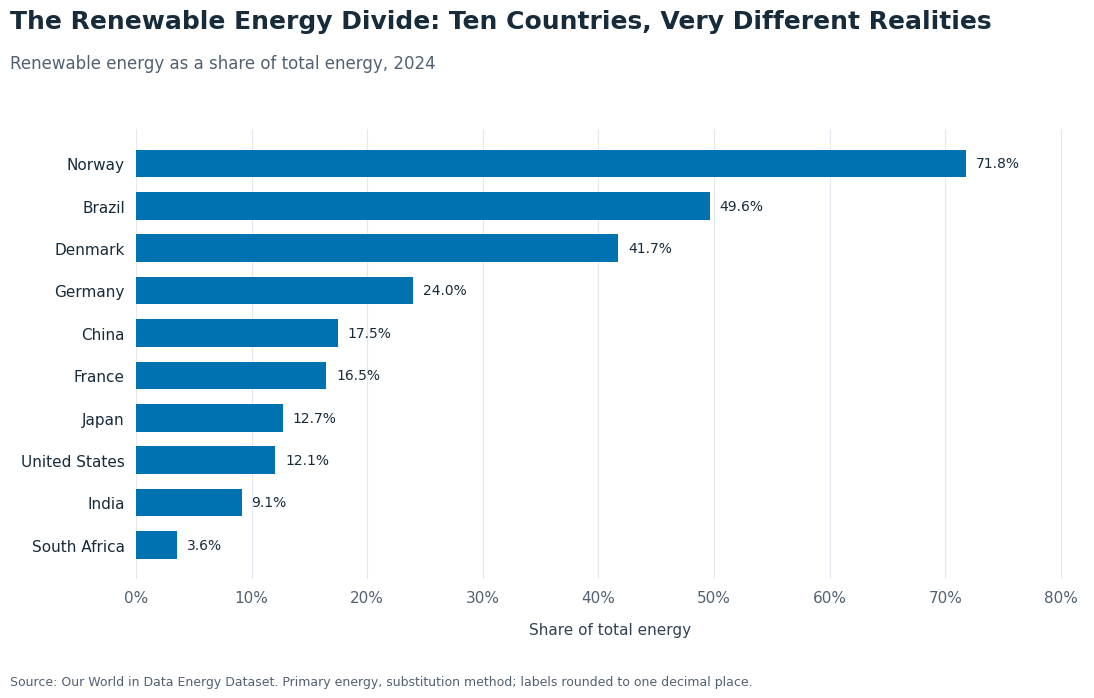

In [3]:
fig, ax = chart_frame(
    "The Renewable Energy Divide: Ten Countries, Very Different Realities",
    "Renewable energy as a share of total energy, 2024",
    "Source: Our World in Data Energy Dataset. Primary energy, substitution method; labels rounded to one decimal place.")
bars = ax.barh(frame["country"], frame["renewables_share_energy"],
               height=0.65, color="#0072B2")
ax.invert_yaxis()
ax.set_xlim(0, 82)
ax.set_xlabel("Share of total energy", labelpad=12)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in frame["renewables_share_energy"]],
             padding=7, fontsize=10, color="#172B3A")
fig.savefig(OUTPUT / "01_renewable_adoption_2024.png", dpi=300, facecolor="white")
plt.show()

**Interpretation.** Norway has the highest renewable share of total energy (71.8%), followed by Brazil (49.6%) and Denmark (41.7%). South Africa has the lowest share (3.6%). The gap between Norway and South Africa is 68.3 percentage points, calculated from unrounded values. The top three all exceed 40%, while each of the other seven remains below 25%. These differences describe the 2024 energy mix; this snapshot alone does not explain their causes.

## Visual 2 - Different Renewable Electricity Pathways
The same country order links this comparison to Visual 1. Stacked horizontal bars show both the combined contribution of three selected sources and the composition of that contribution. A common 0-100% scale represents total electricity generation; the unfilled portion is not classified here. The palette uses distinct blue, orange, and green hues.

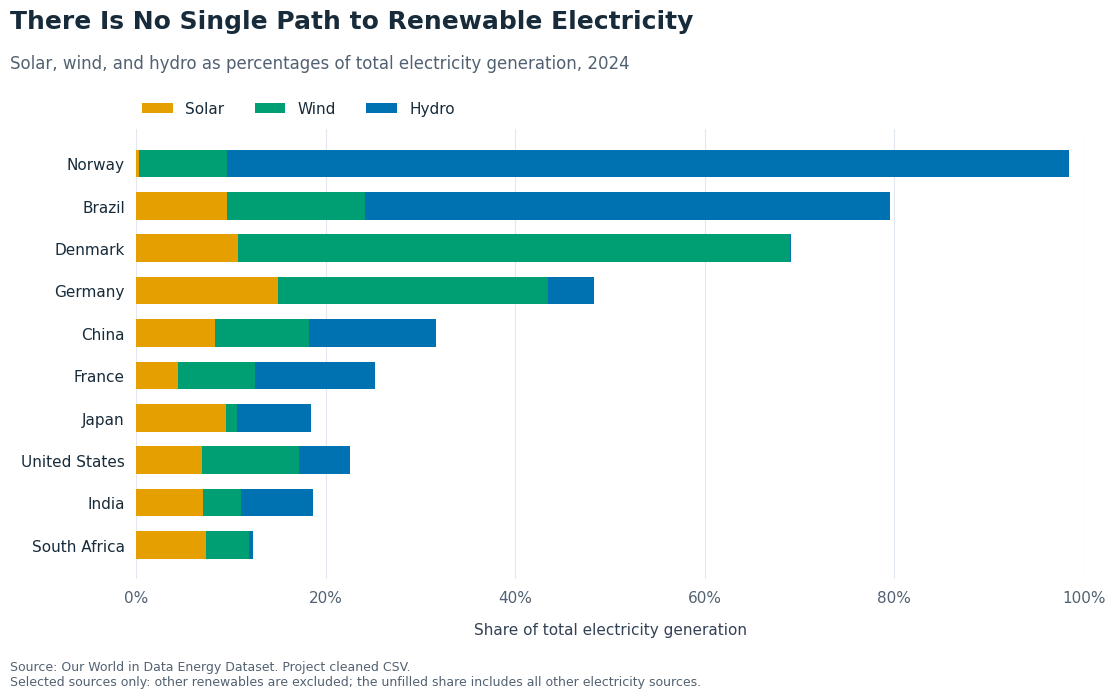

In [4]:
fig, ax = chart_frame(
    "There Is No Single Path to Renewable Electricity",
    "Solar, wind, and hydro as percentages of total electricity generation, 2024",
    "Source: Our World in Data Energy Dataset. Project cleaned CSV.\n"
    "Selected sources only: other renewables are excluded; the unfilled share includes all other electricity sources.")
left = pd.Series(0.0, index=frame.index)
for column, label, color in [
    ("solar_share_elec", "Solar", "#E69F00"),
    ("wind_share_elec", "Wind", "#009E73"),
    ("hydro_share_elec", "Hydro", "#0072B2"),
]:
    ax.barh(frame["country"], frame[column], left=left,
            height=0.65, label=label, color=color)
    left = left + frame[column]
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of total electricity generation", labelpad=12)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.015), ncol=3,
          frameon=False, borderaxespad=0)
fig.savefig(OUTPUT / "02_renewable_electricity_pathways_2024.png", dpi=300, facecolor="white")
plt.show()

**Interpretation and chart choice.** Hydropower supplies 88.8% of Norway's electricity and 55.4% of Brazil's, while wind supplies 58.2% of Denmark's. Germany combines substantial wind (28.5%) and solar (14.9%) shares. These contrasts show different electricity mixes, rather than a single common pathway.

Stacking supports comparison of the three sources' combined shares and their composition. Hydro and wind segments do not all share a baseline, so precise individual comparisons are harder than in separate bar charts. Solar, wind, and hydro do **not** represent all renewable electricity; for example, bioenergy is excluded. This single-year chart does not establish historical transitions.

## Improvements for the final presentation
- Give each chart its own slide and check label and source-note readability at the projected size; keep the denominator explanation visible.
- Use the 68.3 percentage-point adoption gap and the hydro-versus-wind contrast as the spoken takeaways. Describe these as 2024 mixes, not evidence of the speed or causes of transition.
- Keep the country order consistent. If individual electricity-source comparisons become the main question, consider separate aligned bar charts; the current stack prioritizes composition.
- Connect these drafts to the planned GDP and historical visuals only after matching years and checking missing values. These are Milestone 3 drafts for the proposed insights.

## Team Contributions
- **GDP visual - [Team member name]:** Add a comparison of GDP and renewable adoption, documenting the GDP year and any missing values. GDP is missing for 2024 in this CSV, so a different complete year or documented source will be needed.
- **Historical-transition visual - [Team member name]:** Add a time-series view of renewable adoption, documenting the period, country selection, and missing-data treatment.

# Visual 3 — Economic Context

**Insight: Economic size does not automatically determine renewable-energy leadership.**

This exploratory comparison asks whether higher income per person necessarily goes with a higher renewable-energy share. GDP per capita describes income context, while population-sized bubbles retain a sense of country size. It does not test whether GDP causes renewable adoption.

The chart uses renewable energy as a share of **primary energy consumption**, using OWID's legacy substitution method. It does not describe renewable electricity alone or all low-carbon energy: nuclear is excluded. The headline's “greener” refers specifically to renewable-energy share, not overall environmental performance.

The new cells are self-contained and run independently of Visuals 1 and 2. Their palette, typography, white background, and text hierarchy follow the existing drafts.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator, PercentFormatter
from IPython.display import Markdown, display

v3_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "data/energy_10countries_clean.csv").is_file()), None)
if v3_root is None:
    raise FileNotFoundError("Run from within the project repository.")
v3_data = pd.read_csv(v3_root / "data/energy_10countries_clean.csv")
v3_countries = {
    "Germany", "Denmark", "Norway", "France", "China", "United States",
    "India", "Brazil", "Japan", "South Africa",
}
v3_required = ["gdp", "population", "renewables_share_energy"]
v3_sample = v3_data.loc[v3_data["country"].isin(v3_countries)].copy()
assert set(v3_sample["country"]) == v3_countries
assert not v3_sample.duplicated(["country", "year"]).any()
# Require all three observed variables in every country in the same year.
v3_complete = v3_sample.dropna(subset=v3_required)
v3_year_counts = v3_complete.groupby("year")["country"].nunique()
v3_common_years = v3_year_counts.loc[v3_year_counts.eq(len(v3_countries))].index
if len(v3_common_years) == 0:
    raise ValueError("No complete common comparison year exists.")
v3_year = int(v3_common_years.max())
v3_frame = (v3_complete.loc[v3_complete["year"].eq(v3_year)]
            .sort_values("country").copy())
assert len(v3_frame) == len(v3_countries)
assert v3_frame["gdp"].gt(0).all() and v3_frame["population"].gt(0).all()
assert np.isfinite(v3_frame[v3_required].to_numpy()).all()
assert v3_frame["renewables_share_energy"].between(0, 100).all()
# GDP: total international dollars at 2011 prices, PPP-adjusted.
# Population: people. The quotient is 2011 international dollars per person.
v3_frame["gdp_per_capita"] = v3_frame["gdp"] / v3_frame["population"]
assert np.allclose(v3_frame["gdp_per_capita"] * v3_frame["population"],
                   v3_frame["gdp"])
display(Markdown(
    f"**Verified comparison year: {v3_year}.** This is the latest year with GDP, "
    "population, and renewable primary-energy share observed for all ten countries. "
    "GDP per capita is calculated as GDP / population, with no imputation."
))

**Verified comparison year: 2022.** This is the latest year with GDP, population, and renewable primary-energy share observed for all ten countries. GDP per capita is calculated as GDP / population, with no imputation.

## Common year and validation

**The comparison uses 2022**, verified by the preceding completeness check rather than assumed. GDP ends earlier than the energy series. The next table shows all unscaled inputs and the calculated GDP per capita; only display values are rounded. GDP is in international dollars at **2011 prices**, adjusted for purchasing-power differences. It is not current US dollars. Population is in people.

If the dataset is refreshed, rerun the checks and update this explanatory year to match the computed output.

In [6]:
v3_validation = v3_frame[[
    "country", "year", "gdp", "population", "gdp_per_capita",
    "renewables_share_energy",
]].rename(columns={
    "country": "Country", "year": "Year",
    "gdp": "GDP (2011 international $)", "population": "Population (people)",
    "gdp_per_capita": "GDP per capita (2011 international $ / person)",
    "renewables_share_energy": "Renewable share of primary energy (%)",
}).reset_index(drop=True)
display(v3_validation.style.hide(axis="index").format({
    "Year": "{:.0f}", "GDP (2011 international $)": "{:,.0f}",
    "Population (people)": "{:,.0f}",
    "GDP per capita (2011 international $ / person)": "{:,.0f}",
    "Renewable share of primary energy (%)": "{:.2f}",
}))

Country,Year,GDP (2011 international $),Population (people),GDP per capita (2011 international $ / person),Renewable share of primary energy (%)
Brazil,2022,"3,187,412,907,763","210,306,411","15,156",47.66
China,2022,"26,966,016,991,166","1,425,179,562","18,921",15.22
Denmark,2022,"299,429,011,832","5,902,901","50,726",40.79
France,2022,"2,671,568,767,031","66,277,412","40,309",13.73
Germany,2022,"3,909,612,753,939","84,086,227","46,495",20.33
India,2022,"10,476,248,645,535","1,425,423,209","7,350",9.42
Japan,2022,"4,774,494,846,664","124,997,585","38,197",11.15
Norway,2022,"482,328,451,592","5,456,796","88,390",69.65
South Africa,2022,"723,559,323,969","62,378,417","11,600",3.65
United States,2022,"19,493,170,182,843","341,534,041","57,075",10.88


## Visual draft

A linear x-axis keeps income differences interpretable in their original units. Bubble **area is proportional to population**, with the same blue used for adoption in Visual 1. The population legend gives a size reference; smaller countries remain labeled. The y-axis starts at zero. No fitted trend line is used for this small, deliberately selected sample.

A high renewable share is not a measure of total renewable generation, and it does not alone establish low emissions or environmental leadership.

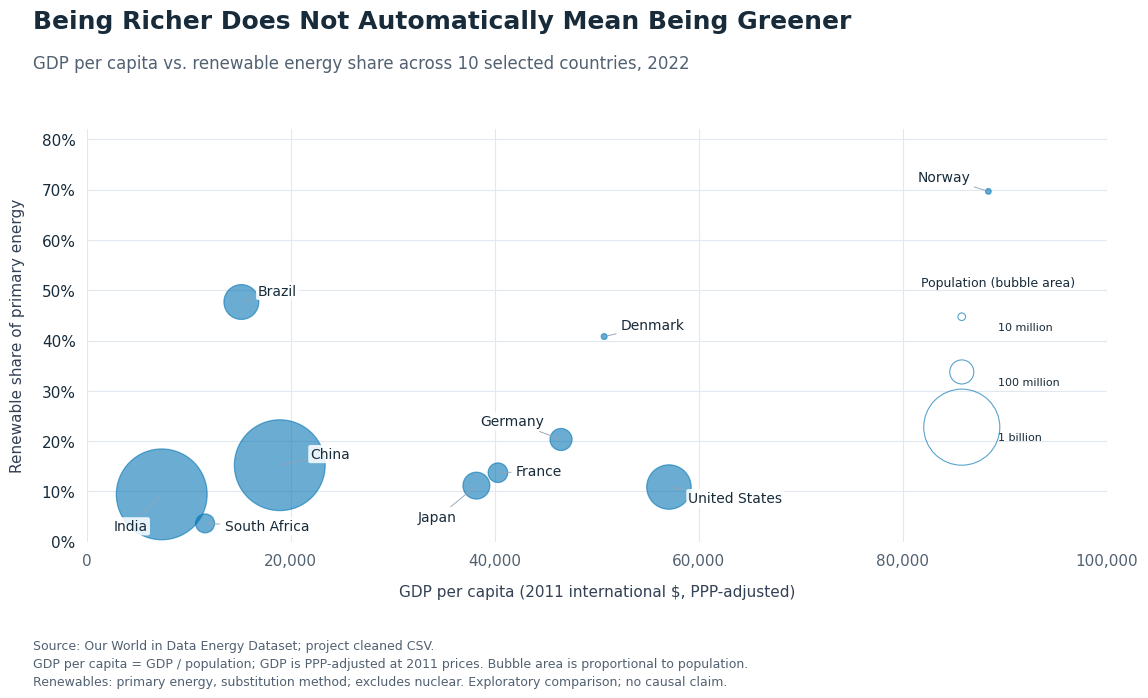

Saved: visuals\03_gdp_vs_renewables.png (300 dpi)


In [7]:
# A local style context follows Meriam's design without changing global styling.
v3_style = {
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.labelcolor": "#334155", "text.color": "#172B3A",
    "xtick.color": "#526171", "ytick.color": "#172B3A",
    "figure.facecolor": "white", "axes.facecolor": "white",
}
v3_output = v3_root / "visuals" / "03_gdp_vs_renewables.png"
v3_output.parent.mkdir(exist_ok=True)
v3_area_per_million = 3.0  # scatter marker area in points squared per million people
v3_offsets = {
    "India": (-10, -23), "China": (22, 8), "South Africa": (14, -2),
    "Brazil": (12, 8), "Japan": (-14, -23), "France": (13, 1),
    "Germany": (-12, 13), "Denmark": (12, 8),
    "United States": (14, -8), "Norway": (-13, 10),
}
with plt.rc_context(v3_style):
    v3_fig, v3_ax = plt.subplots(figsize=(12, 7.5))
    v3_fig.subplots_adjust(left=0.10, right=0.95, top=0.79, bottom=0.24)
    v3_fig.text(0.055, 0.95,
                "Being Richer Does Not Automatically Mean Being Greener",
                fontsize=18, weight="bold", va="top")
    v3_fig.text(0.055, 0.89,
                f"GDP per capita vs. renewable energy share across 10 selected countries, {v3_year}",
                fontsize=12, color="#526171", va="top")
    v3_ax.set_axisbelow(True)
    v3_ax.grid(color="#E2E8F0", linewidth=0.8)
    v3_ax.tick_params(axis="both", length=0, pad=8)
    v3_ax.scatter(
        v3_frame["gdp_per_capita"], v3_frame["renewables_share_energy"],
        s=v3_frame["population"] / 1_000_000 * v3_area_per_million,
        color="#0072B2", alpha=0.58, edgecolors="#0072B2", linewidths=0.9,
        zorder=3,
    )
    for v3_row in v3_frame.itertuples(index=False):
        v3_dx, v3_dy = v3_offsets[v3_row.country]
        v3_ax.annotate(
            v3_row.country, (v3_row.gdp_per_capita, v3_row.renewables_share_energy),
            xytext=(v3_dx, v3_dy), textcoords="offset points",
            ha="right" if v3_dx < 0 else "left", va="center", fontsize=10,
            color="#172B3A", zorder=4,
            bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85},
            arrowprops={"arrowstyle": "-", "color": "#94A3B8", "lw": 0.65},
        )
    v3_ax.set_xlim(0, 100_000)
    v3_ax.set_ylim(0, 82)
    v3_ax.xaxis.set_major_locator(MultipleLocator(20_000))
    v3_ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
    v3_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    v3_ax.set_xlabel("GDP per capita (2011 international $, PPP-adjusted)", labelpad=12)
    v3_ax.set_ylabel("Renewable share of primary energy", labelpad=12)
    # Keep reference areas faithful to the data; hollow circles reduce visual weight.
    v3_legend = [v3_ax.scatter([], [], s=p * v3_area_per_million,
                              facecolors="none", edgecolors="#0072B2",
                              alpha=0.65, linewidths=0.8)
                 for p in (10, 100, 1000)]
    v3_ax.legend(v3_legend, ["10 million", "100 million", "1 billion"],
                 title="Population (bubble area)", loc="upper right", ncol=1,
                 bbox_to_anchor=(0.98, 0.67),
                 frameon=False, fontsize=8, title_fontsize=9,
                 labelspacing=1.8, borderpad=0.5, handletextpad=1.0,
                 handleheight=4.5, handlelength=4.5)
    v3_fig.text(0.055, 0.045,
                "Source: Our World in Data Energy Dataset; project cleaned CSV.\n"
                "GDP per capita = GDP / population; GDP is PPP-adjusted at 2011 prices. Bubble area is proportional to population.\n"
                "Renewables: primary energy, substitution method; excludes nuclear. Exploratory comparison; no causal claim.",
                fontsize=9, color="#526171", va="bottom", linespacing=1.5)
    v3_fig.savefig(v3_output, dpi=300, facecolor="white")
    plt.show()
    plt.close(v3_fig)
assert v3_output.is_file() and v3_output.stat().st_size > 0
print(f"Saved: {v3_output.relative_to(v3_root)} (300 dpi)")

## Interpretation

Richer countries do **not always** have higher renewable-energy shares. In the common comparison year, Brazil has a higher renewable share than several richer countries, including the United States, Germany, France, and Japan. Denmark also has a higher share than the United States despite lower GDP per capita.

Norway stands out for both high GDP per capita and a high renewable share; Brazil stands out for a high renewable share at a much lower income level. The United States has relatively high income but a comparatively modest renewable share. These are descriptive contrasts, not statistically identified outliers. The large bubbles for China and India also show that population size alone does not establish renewable-share leadership.

The overall pattern suggests a positive association between income per person and renewable share in this selected sample, with substantial variation. Income **does not appear to be sufficient to explain** renewable-share leadership. This supports Insight 3 as a statement that size alone is not decisive, rather than a claim that income has no relationship with renewables. The original insight refers to total economic size; this chart examines income per person and population, complementing the total-GDP comparison in Milestone 2.

**Wording refinement:** “Higher income does not guarantee a higher renewable-energy share” is more precise for this chart than treating “greener” as a broad environmental claim. Renewables exclude nuclear, which is especially relevant when interpreting France. The chart does not identify causes or establish how income affects adoption.

## Visual 4: Renewable transition over time

**Insight 4:** Countries have made very different gains in renewable-energy share since 2000.

- Variable: `renewables_share_energy` (renewables as % of primary energy, OWID)
- Period: 2000 to the latest year with data for all 10 countries (2024)
- Format: small multiples, one panel per country, ordered by gain since 2000. Each country is highlighted in green with the other nine in grey, so every panel can be compared to the group without ten overlapping colours.
- Gain is measured in **percentage points (pp)** = 2024 value minus 2000 value.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/energy_10countries_clean.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from within the project repository.")

df = pd.read_csv(ROOT / "data/energy_10countries_clean.csv")

COUNTRIES = ["Germany", "Denmark", "Norway", "France", "China",
             "United States", "India", "Brazil", "Japan", "South Africa"]
VAR = "renewables_share_energy"
START_YEAR = 2000

ts = df.loc[df["country"].isin(COUNTRIES), ["country", "year", VAR]]

# Available years and missing values per country
check = (ts.dropna(subset=[VAR])
           .groupby("country")["year"]
           .agg(first_year="min", last_year="max", n_years="count"))

# Latest year with values for ALL 10 countries (common end year)
complete = ts.dropna(subset=[VAR]).groupby("year")["country"].nunique()
END_YEAR = int(complete[complete == len(COUNTRIES)].index.max())

check["missing_in_period"] = (
    ts[ts["year"].between(START_YEAR, END_YEAR)]
      .groupby("country")[VAR].apply(lambda s: s.isna().sum())
)
print(check)
print(f"Period used: {START_YEAR}-{END_YEAR}")

               first_year  last_year  n_years  missing_in_period
country                                                         
Brazil               2000       2024       25                  0
China                2000       2024       25                  0
Denmark              2000       2024       25                  0
France               2000       2024       25                  0
Germany              2000       2024       25                  0
India                2000       2024       25                  0
Japan                2000       2024       25                  0
Norway               2000       2024       25                  0
South Africa         2000       2024       25                  0
United States        2000       2024       25                  0
Period used: 2000-2024


In [10]:
wide = (ts[ts["year"].between(START_YEAR, END_YEAR)]
          .pivot(index="year", columns="country", values=VAR))
assert wide.isna().sum().sum() == 0, "Missing values inside the period"

summary = pd.DataFrame({
    "share_start": wide.loc[START_YEAR],
    "share_end": wide.loc[END_YEAR],
})
summary["change_pp"] = summary["share_end"] - summary["share_start"]
summary = summary.sort_values("change_pp", ascending=False)
print(summary.round(1))

               share_start  share_end  change_pp
country                                         
Denmark                6.8       41.7       35.0
Germany                2.7       24.0       21.2
China                  5.3       17.5       12.1
France                 6.4       16.5       10.1
Brazil                40.9       49.6        8.7
United States          3.9       12.0        8.2
Japan                  4.6       12.7        8.1
South Africa           0.4        3.6        3.2
India                  6.0        9.1        3.1
Norway                70.8       71.8        1.0


FileExistsError: c:\Users\ghada\DataStory_Energy\visuals\04_transition_over_time.png already exists; not overwriting it.

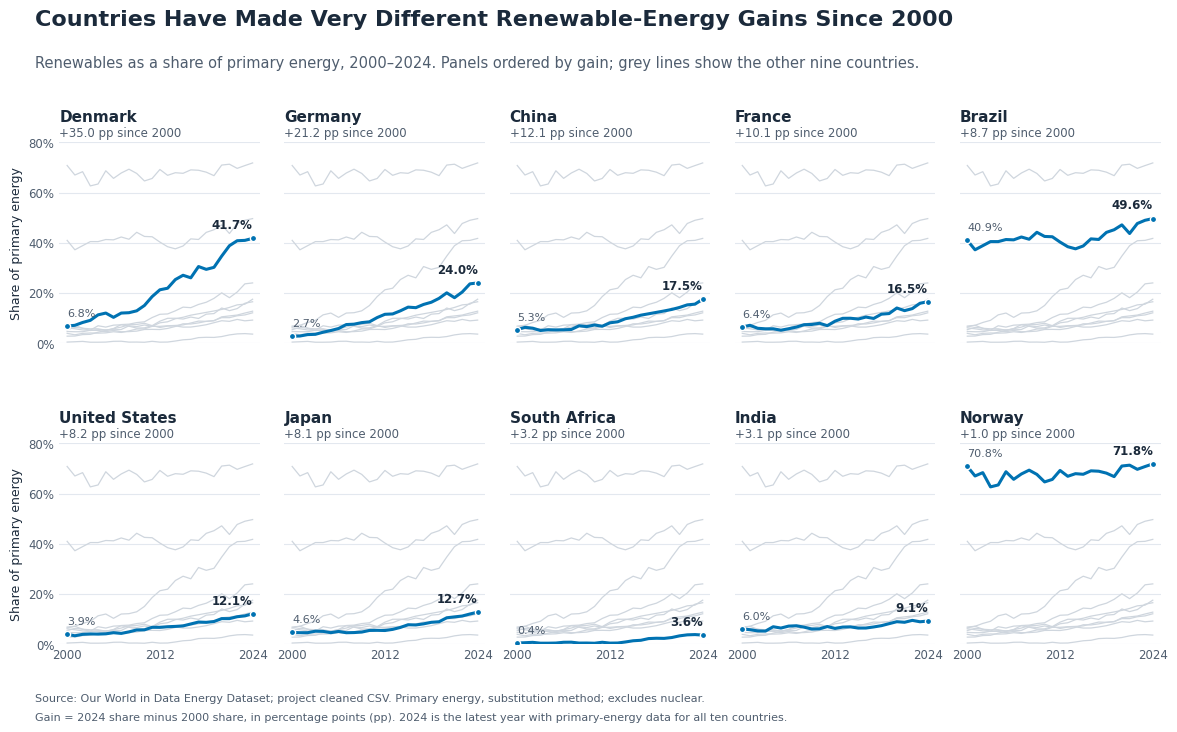

In [14]:
# Style matched to Visuals 1-3
TITLE = "#1b2a3b"
SUBTITLE = "#4f5d6e"
TEXT = "#1b2a3b"
GRID = "#e3e8ef"
HIGHLIGHT = "#0072B2"   # same blue as Visual 1
CONTEXT = "#cfd6de"     # other nine countries, muted

plt.rcParams.update({"font.family": "DejaVu Sans"})

fig, axes = plt.subplots(2, 5, figsize=(12.1, 7.6), sharex=True, sharey=True)
years = wide.index

for ax, country in zip(axes.flat, summary.index):
    for other in wide.columns:
        if other != country:
            ax.plot(years, wide[other], color=CONTEXT, lw=0.9, zorder=1)
    y = wide[country]
    ax.plot(years, y, color=HIGHLIGHT, lw=2.2, zorder=3)
    ax.scatter([START_YEAR, END_YEAR], [y.iloc[0], y.iloc[-1]], s=20,
               color=HIGHLIGHT, edgecolor="white", linewidth=1, zorder=4)

    ax.annotate(f"{y.iloc[0]:.1f}%", (START_YEAR, y.iloc[0]),
                xytext=(0, 7), textcoords="offset points",
                ha="left", fontsize=8, color=SUBTITLE)
    ax.annotate(f"{y.iloc[-1]:.1f}%", (END_YEAR, y.iloc[-1]),
                xytext=(0, 7), textcoords="offset points",
                ha="right", fontsize=8.5, color=TEXT, fontweight="bold")

    change = summary.loc[country, "change_pp"]
    ax.set_title(country, loc="left", fontsize=11, fontweight="bold",
                 color=TEXT, pad=15)
    ax.text(0, 1.015, f"{change:+.1f} pp since {START_YEAR}",
            transform=ax.transAxes, fontsize=8.5, color=SUBTITLE, va="bottom")

    ax.set_ylim(0, 80)
    ax.set_xlim(START_YEAR - 1, END_YEAR + 1)
    ax.set_xticks([START_YEAR, 2012, END_YEAR])
    ax.set_yticks([0, 20, 40, 60, 80])
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=SUBTITLE, length=0, labelsize=8.5)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

for ax in axes[:, 0]:
    ax.set_ylabel("Share of primary energy", color=TEXT, fontsize=9)

fig.text(0.055, 0.955, "Countries Have Made Very Different Renewable-Energy Gains Since 2000",
         ha="left", va="top", fontsize=16, fontweight="bold", color=TITLE)
fig.text(0.055, 0.895,
         f"Renewables as a share of primary energy, {START_YEAR}–{END_YEAR}. "
         "Panels ordered by gain; grey lines show the other nine countries.",
         ha="left", va="top", fontsize=10.5, color=SUBTITLE)
fig.text(0.055, 0.045,
         "Source: Our World in Data Energy Dataset; project cleaned CSV. "
         "Primary energy, substitution method; excludes nuclear.",
         ha="left", fontsize=8, color=SUBTITLE)
fig.text(0.055, 0.02,
         f"Gain = {END_YEAR} share minus {START_YEAR} share, in percentage points (pp). "
         f"{END_YEAR} is the latest year with primary-energy data for all ten countries.",
         ha="left", fontsize=8, color=SUBTITLE)

fig.subplots_adjust(left=0.075, right=0.985, top=0.78, bottom=0.12,
                    hspace=0.5, wspace=0.12)

Path("visuals").mkdir(exist_ok=True)
out = ROOT / "visuals" / "04_transition_over_time.png"
if out.exists():
    raise FileExistsError(f"{out} already exists; not overwriting it.")
fig.savefig(out, dpi=300, facecolor="white")
plt.show()

### Interpretation

- **Largest cumulative gains:** Denmark shows the largest increase (+35.0 pp, from 6.8% to 41.7%), followed by Germany (+21.2 pp, from 2.7% to 24.0%). China (+12.1 pp) and France (+10.1 pp) form a second group.
- **Started high and stayed high:** Norway was already at 70.8% in 2000 and remained at a high level, between about 63% and 72%, ending at 71.8% (+1.0 pp). Brazil also started high (40.9%) and reached 49.6% (+8.7 pp), with a dip in the early 2010s before rising again.
- **Remain relatively low:** South Africa (3.6%) and India (9.1%) had the smallest gains apart from Norway, about +3 pp each. The United States and Japan rose by about 8 pp but remain near 12–13%.
- **Different trajectories:** For most countries, the larger part of the gain came after about 2010. Denmark gained 8.2 pp in 2000–2010 and 26.7 pp in 2010–2024; China, the United States and Japan changed little before 2010. Norway's small change reflects its high starting level rather than an absence of renewables.

**What this suggests:** the countries did not follow one common path. Some started from a high base, some built up their share substantially over the period, and others changed only slightly. This supports the idea that there is no single renewable-energy pathway.

*Note:* changes are in percentage points of primary energy (substitution method). Renewables exclude nuclear, which is relevant when interpreting France. This chart describes trends and does not explain their causes.